In [25]:
#Team Member:

#Name: MUHAMMAD IQMAL HAIKAL BIN MANSOR
#Matric: A221017

#Name: MUHAMMAD SHAFIQ BIN SHAHRIL
#Matric: A200426

#Name: SHARUL AMIR BIN SHARUDDIN
#Matric: A216638

#Name: AMIRUL HAKIMI BIN ROSLI
#Matric: A220996

In [24]:
#Scenario: Online Retail Sales Transaction Data Quality Assessment

# The dataset contains sales transactions from a UK-based online retail business
# selling gifts and homeware products to customers from different countries.
# This dataset may contain missing customer information, duplicate transactions,
# unusual product quantities, cancelled orders and potential customer privacy
# risks.

#Question to answer:

#-Are there missing values and duplicate transaction records?
#-Are there unusual prices or product quantities?
#-Are there incorrect data types or invalid transaction records?

In [ ]:
#Data source

#Dataset: Sales Transaction v.4a.csv
#Platform: Kaggle
#Dataset Links: https://www.kaggle.com/datasets/gabrielramos87/an-online-shop-business
#How Obtained: Downloaded the CSV dataset and uploaded it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

df = pd.read_csv("Sales Transaction v.4a.csv")

print("Dataset loaded successfully!")

Saving Sales Transaction v.4a.csv to Sales Transaction v.4a.csv
Dataset loaded successfully!


In [3]:
# Display first 5 rows
df.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.0,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom


In [4]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (536350, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           536350 non-null  object 
 2   ProductNo      536350 non-null  object 
 3   ProductName    536350 non-null  object 
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.7+ MB


,Price,Quantity,CustomerNo
count,536350.000000,536350.000000,536295.000000
mean,12.662182,9.919347,15227.893178
std,8.490450,216.662300,1716.582932
min,5.130000,-80995.000000,12004.000000
25%,10.990000,1.000000,13807.000000
50%,11.940000,3.000000,15152.000000
75%,14.090000,10.000000,16729.000000
max,660.620000,80995.000000,18287.000000


In [5]:
# Count missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Percentage:")
print(missing_percentage)

Missing Values:
TransactionNo     0
Date              0
ProductNo         0
ProductName       0
Price             0
Quantity          0
CustomerNo       55
Country           0
dtype: int64

Missing Percentage:
TransactionNo    0.000000
Date             0.000000
ProductNo        0.000000
ProductName      0.000000
Price            0.000000
Quantity         0.000000
CustomerNo       0.010254
Country          0.000000
dtype: float64


In [6]:
# Create a missing customer indicator
df['CustomerNo_Missing'] = df['CustomerNo'].isnull()

# Do not impute customer numbers because they are identifiers
print("Missing customer numbers:",
      df['CustomerNo'].isnull().sum())

print("Missing customer percentage:",
      round(df['CustomerNo'].isnull().mean() * 100, 4), "%")

# The dataset contains 55 missing values in the CustomerNo column.Instead of
# replacing them with artificial customer numbers, a missing-value indicator was
# created to identify records with unknown customers. This prevents inaccurate
# customer identification. %% Function to detect outliers

Missing customer numbers: 55
Missing customer percentage: 0.0103 %


In [7]:
# Function to detect outliers
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print("\nColumn:", column)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

    return outliers

# Detect outliers
price_outliers = detect_outliers(df, 'Price')
quantity_outliers = detect_outliers(df, 'Quantity')


Column: Price
Lower Bound: 6.340000000000001
Upper Bound: 18.74
Number of Outliers: 99142

Column: Quantity
Lower Bound: -12.5
Upper Bound: 23.5
Number of Outliers: 57371


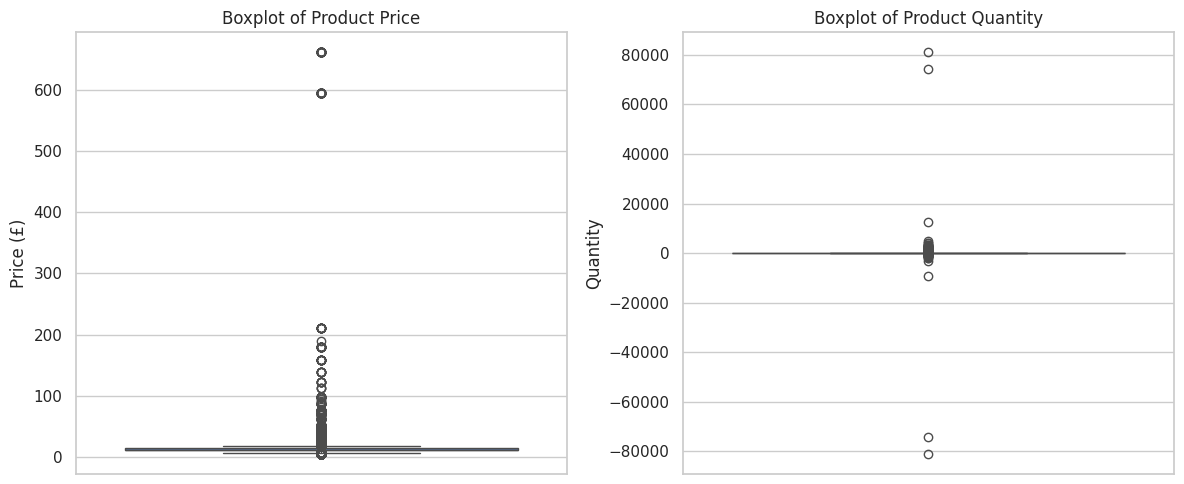

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Price'], ax=axes[0])
axes[0].set_title("Boxplot of Product Price")
axes[0].set_ylabel("Price (£)")

sns.boxplot(y=df['Quantity'], ax=axes[1])
axes[1].set_title("Boxplot of Product Quantity")
axes[1].set_ylabel("Quantity")

plt.tight_layout()
plt.show()

In [9]:
# Create IQR outlier flags
for column in ['Price', 'Quantity']:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column + '_Outlier'] = (
        (df[column] < lower) |
        (df[column] > upper)
    )

print("Price outliers:",
      df['Price_Outlier'].sum())

print("Quantity outliers:",
      df['Quantity_Outlier'].sum())

# Outliers were detected using the IQR method and visualised using boxplots.
# Some transactions contain unusually high prices and quantities. These records
# were retained and flagged because they may represent genuine bulk purchases
# rather than incorrect data. Negative quantities were also identified as
# cancellation records and should not be treated as ordinary sales. %% Count
# duplicate records

Price outliers: 99142
Quantity outliers: 57371


In [10]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 5200


In [11]:
# Remove exact duplicate records
df = df.drop_duplicates()

print("Dataset after removing duplicates:")
print(df.shape)

print("Remaining duplicates:", df.duplicated().sum())

#These records were removed to prevent repeated transaction lines from affecting data analysis.

Dataset after removing duplicates:
(531150, 11)
Remaining duplicates: 0


In [12]:
# Convert Date into datetime format
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

# Convert CustomerNo into string format
df['CustomerNo'] = df['CustomerNo'].astype('Int64').astype('string')

# Convert transaction and product numbers into string
df['TransactionNo'] = df['TransactionNo'].astype('string')
df['ProductNo'] = df['ProductNo'].astype('string')

# Display updated data types
df.info()

# The Date column was converted from object to datetime format to support
# accurate date handling. CustomerNo, TransactionNo and ProductNo were converted
# into string formats because they represent identifiers rather than numerical
# measurements. %% Identify cancelled transactions

<class 'pandas.core.frame.DataFrame'>
Index: 531150 entries, 0 to 536349
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   TransactionNo       531150 non-null  string        
 1   Date                531150 non-null  datetime64[ns]
 2   ProductNo           531150 non-null  string        
 3   ProductName         531150 non-null  object        
 4   Price               531150 non-null  float64       
 5   Quantity            531150 non-null  int64         
 6   CustomerNo          531095 non-null  string        
 7   Country             531150 non-null  object        
 8   CustomerNo_Missing  531150 non-null  bool          
 9   Price_Outlier       531150 non-null  bool          
 10  Quantity_Outlier    531150 non-null  bool          
dtypes: bool(3), datetime64[ns](1), float64(1), int64(1), object(2), string(3)
memory usage: 38.0+ MB


In [13]:
# Identify cancelled transactions
df['Cancelled'] = df['TransactionNo'].str.startswith('C')

print("Cancelled Transactions:",
      df['Cancelled'].sum())

print("Normal Transactions:",
      (~df['Cancelled']).sum())

# Check negative quantities
print("Negative Quantity Records:",
      (df['Quantity'] < 0).sum())

Cancelled Transactions: 8548
Normal Transactions: 522602
Negative Quantity Records: 8548


In [14]:
# Check invalid prices
print("Zero or Negative Prices:",
      (df['Price'] <= 0).sum())

# Check invalid quantities
print("Zero Quantities:",
      (df['Quantity'] == 0).sum())

# Check invalid dates
print("Invalid Dates:",
      df['Date'].isnull().sum())

# Check blank product names
print("Blank Product Names:",
      df['ProductName'].astype(str).str.strip().eq('').sum())

# These records were retained and labelled rather than removed because they
# contain important transaction information. No zero or negative prices were
# found.

Zero or Negative Prices: 0
Zero Quantities: 0
Invalid Dates: 0
Blank Product Names: 0


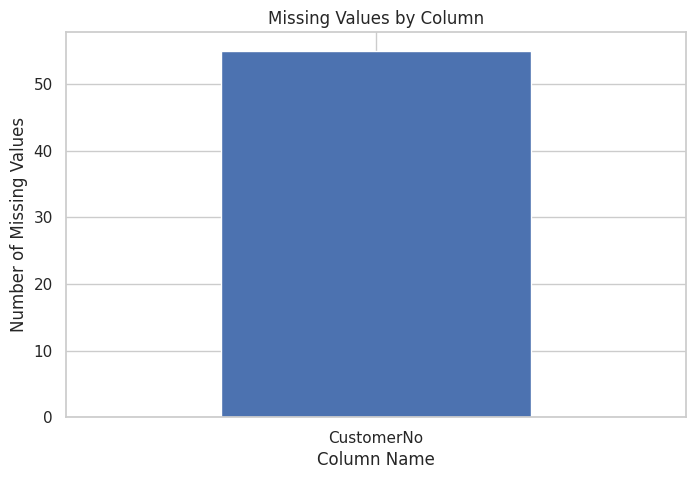

In [15]:
missing = df.isnull().sum()
missing = missing[missing > 0]

plt.figure(figsize=(8, 5))

missing.plot(kind='bar')

plt.title("Missing Values by Column")
plt.xlabel("Column Name")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)

plt.show()

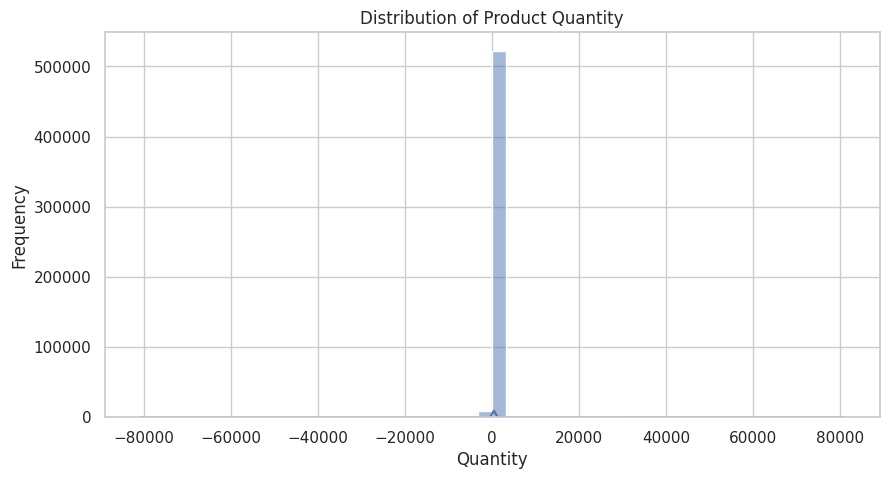

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Quantity'],
    bins=50,
    kde=True
)

plt.title("Distribution of Product Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

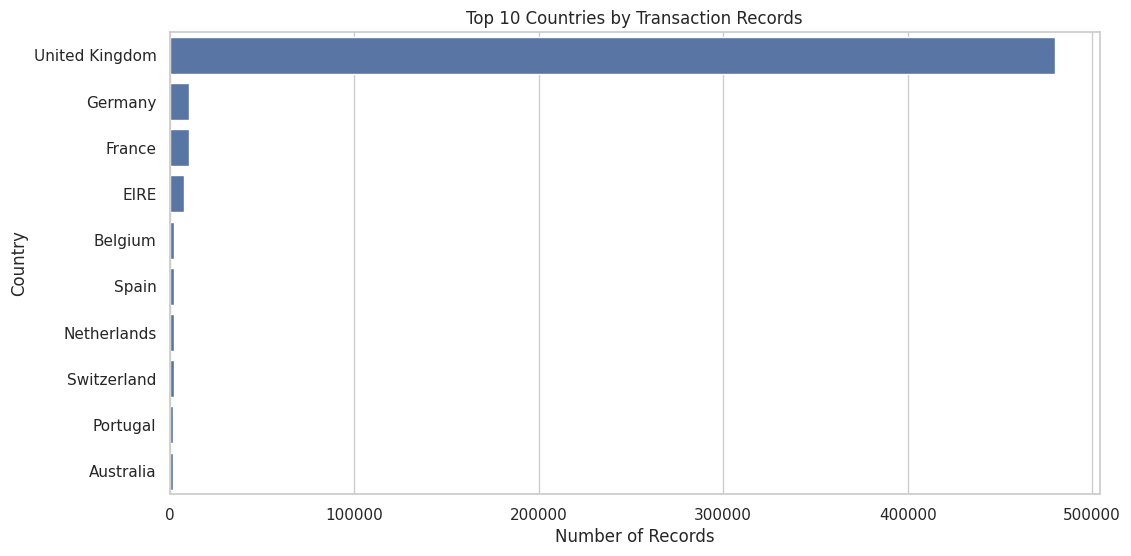

In [17]:
plt.figure(figsize=(12, 6))

country_counts = df['Country'].value_counts().head(10)

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Transaction Records")
plt.xlabel("Number of Records")
plt.ylabel("Country")

plt.show()

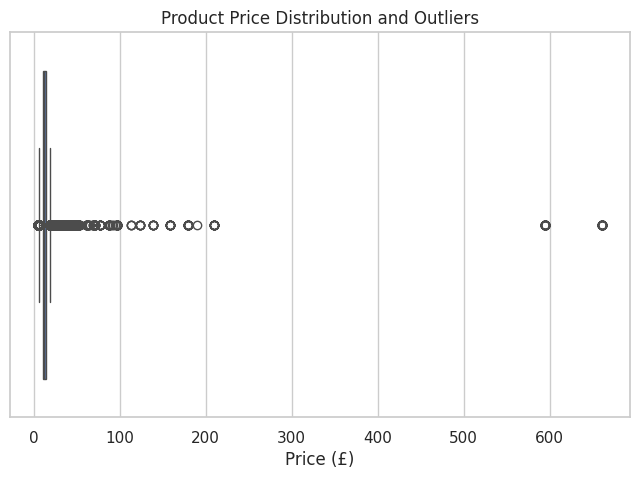

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Price'])

plt.title("Product Price Distribution and Outliers")
plt.xlabel("Price (£)")

plt.show()

In [20]:
#PII risks:

# The CustomerNo column contains customer identifiers that could potentially be
# used to link transactions to individual customers. Although the dataset does
# not directly contain names, email addresses or phone numbers, customer
# identifiers should still be protected. CustomerNo should be anonymised or
# removed before sharing the dataset publicly.

#Bias risks:

# The dataset contains a significant imbalance in geographical representation.
# Approximately 90.37% of the records belong to the United Kingdom, while other
# countries contribute much smaller proportions. This may cause analysis to
# overrepresent UK customer behaviour and underrepresent international
# customers.

#How to handle these risks:

#-Anonymise customer identifiers before sharing data.
#-Avoid exposing individual customer transaction records.
#-Consider geographical imbalance when interpreting results.
#-Avoid assuming that UK customer behaviour represents all customers.

In [ ]:
#Conclusion

# The data profiling process identified several data quality issues in the sales
# transaction dataset, including 55 missing customer numbers, 5,200 duplicate
# records, unusual prices and quantities, and cancelled transactions. Duplicate
# records were removed, missing customer identifiers were flagged, and incorrect
# data types were converted. Outliers and cancelled transactions were retained
# because they may represent genuine business activities. Overall, the cleaned
# dataset is suitable for retail transaction analysis, but limitations such as
# missing customer information, extreme values and geographical imbalance should
# be considered when interpreting the results.